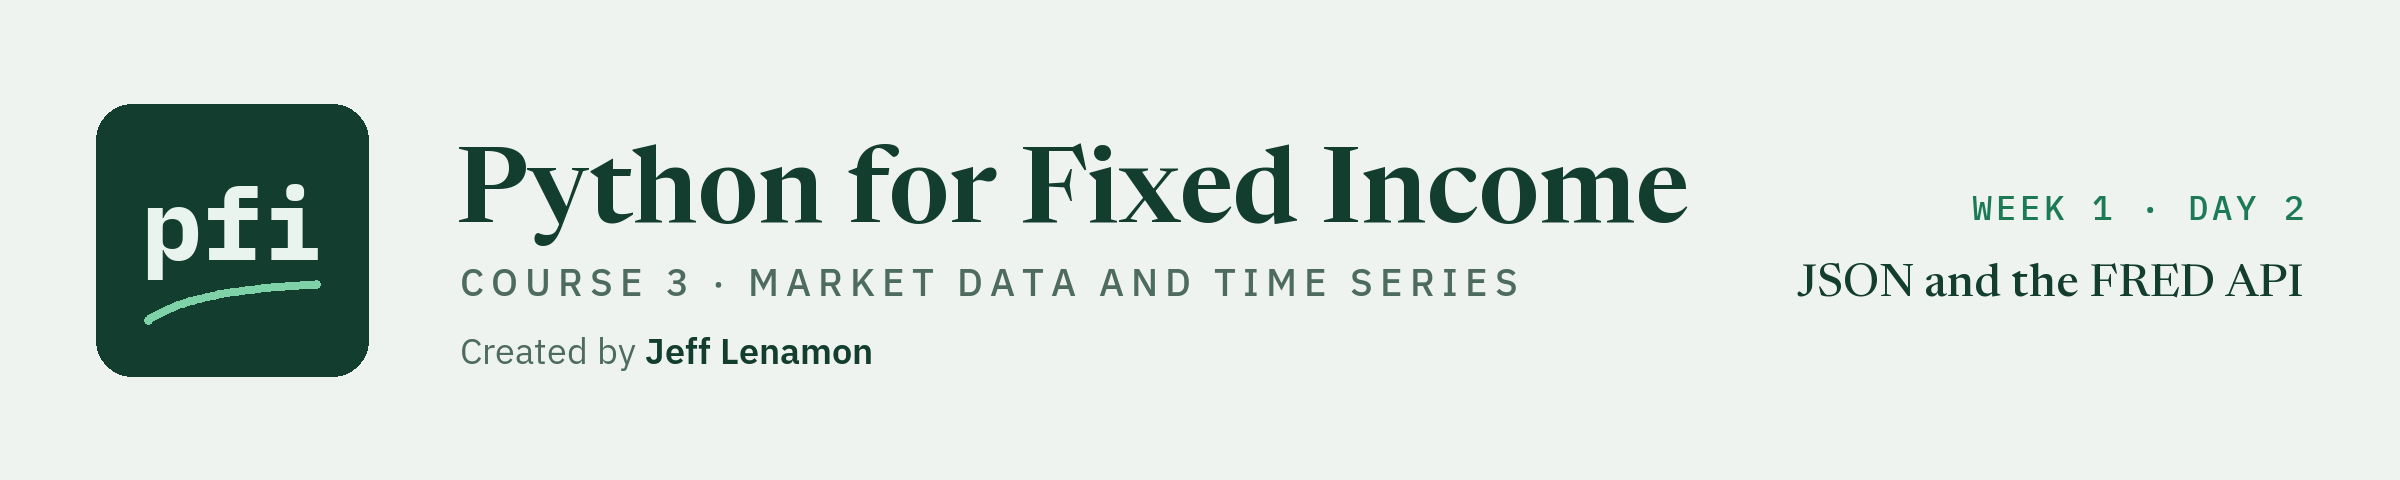

# JSON and the FRED API

Week 1, Day 2. FRED's answer read as JSON, its missing day kept as `NaN` and never 0, three tested functions that pull a series without showing the key, and a live pull tied to the Treasury file.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day2/02_json_and_the_fred_api.ipynb)

### The Desk Lead's Note

> Yesterday FRED's answer came back as text, its yields in quotes. Make it a dated series the desk can trust. Show me what is in the answer, and what FRED writes on a weekday with no yield. Prove a missing day never becomes a zero: show me what a zero would do. Put the request, the reading and the download in `marketdata.py`, tested without the network, with errors that never show a key. Pull the 10-year and the 2-year from 2015 and tie them to the Treasury file, inside FRED's limit. Then read exactly what you are about to commit, and scan it for anything shaped like a key.

Every cell runs without a key; the saved outputs are that run, and every demo uses the course's fake key.

**FRED's numbers arrive as text, and one of them is a dot: today it becomes `NaN`, never 0.**

### Start the Day

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 01 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(2)

Work folder pfi_course3_02_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 01 left it, 1 commit


`start_day(2)` copied in the Treasury file, two answers in FRED's format, and notebook 01's committed files.

### Imports and the House Colours

In [2]:
import importlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import marketdata as md

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the course's fake key, as in notebook 01: the shape of a FRED key, obviously not one
FAKE_KEY = 'fakefakefakefakefakefakefakefake'

### The Module So Far

In [3]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....                                                                     [100%]
4 passed in 0.50s



## 2.1 JSON, Read by Python

Notebook 01 ended on FRED's `"5.29"`, in quotes: text, not yet a number.
That answer is **JSON**, the text format web APIs answer in, and the one an AI assistant replies in when you ask it for structured data.
JSON has two containers: an **object** `{ }` of `"name": value` pairs, and a **list** `[ ]` of values in order.
Inside them sit text in quotes, numbers, `true`, `false`, and `null`.

### Two Days of the 10-Year, as JSON

In [4]:
# two days of the 10-year in FRED's shape, plus true and null to show every kind of value
text = '''{"units": "lin", "complete": true, "notes": null,
 "observations": [{"date": "2026-09-29", "value": "5.26"},
                  {"date": "2026-09-30", "value": "5.29"}]}'''
# json.loads reads JSON text into Python's own containers
reply = json.loads(text)
print(type(reply), type(reply['observations']))

<class 'dict'> <class 'list'>


### What Each Value Became

In [5]:
# each value, with !r showing text in its quotes, and the type Python gave it
for name in ['units', 'complete', 'notes']:
    print(f'{name}: {reply[name]!r}, {type(reply[name]).__name__}')
latest = reply['observations'][-1]['value']
print(f'value: {latest!r}, {type(latest).__name__}')

units: 'lin', str
complete: True, bool
notes: None, NoneType
value: '5.29', str


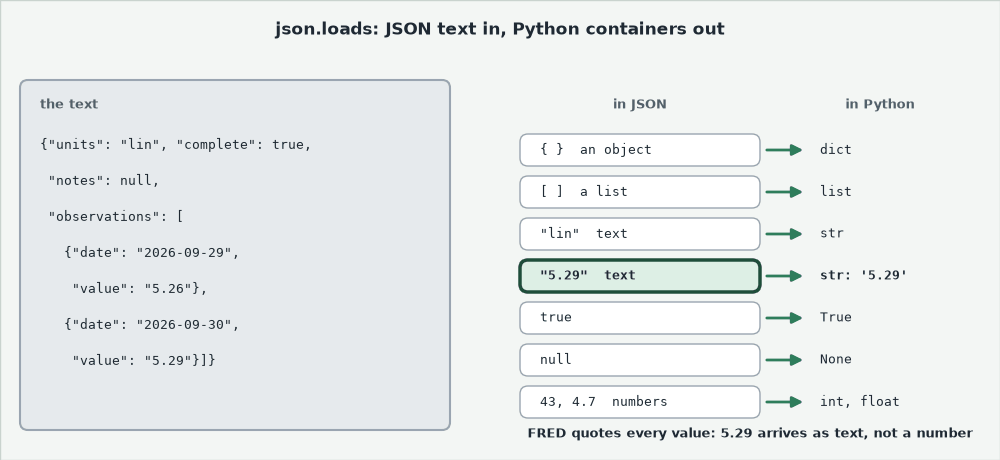

An object became a `dict` and a list a `list`.
`5.29` stayed text: FRED quotes every value.

**Predict 1**

Q. A Python dictionary, printed, looks a lot like JSON. Hand that printed text to `json.loads`:

A) it reads it
B) it stops with an error
C) it reads it with every value as text

### Hand Python's Text to `json.loads`

In [6]:
# str() gives the text Python prints for the dictionary
json.loads(str(reply))

JSONDecodeError: Expecting property name enclosed in double quotes: line 1 column 2 (char 1)

B: Python writes text in single quotes and `True` and `None`; JSON wants double quotes, `true` and `null`.
The two look alike and are different formats.

> STORY: FRED's own help pages say that "Before the popularization of the World Wide Web, the data were provided in list form on a dial-in, electronic bulletin board system." The same numbers now come back as JSON from a URL. Source: FRED Help, "What is FRED?", https://fred.stlouisfed.org/help/about/about-fred/what-is-fred/ (read 2026-11-08).

**JSON is two containers and a few plain values; `json.loads` makes them a `dict` and a `list`, and FRED's 5.29 arrives as the text `'5.29'`.**

## 2.2 FRED's Answer, Field by Field

Now the real answer.
The course built this sample from the Treasury file in FRED's exact layout; nothing in it was downloaded from FRED.

### Read the Sample

In [7]:
# read_text reads a whole file as one text; json.loads turns it into a dict
payload = json.loads(Path('course3_fred_format_dgs10.json').read_text(encoding='utf-8'))
print(list(payload))
print('count:', payload['count'])

['realtime_start', 'realtime_end', 'observation_start', 'observation_end', 'units', 'output_type', 'file_type', 'order_by', 'sort_order', 'count', 'offset', 'limit', 'observations']
count: 43


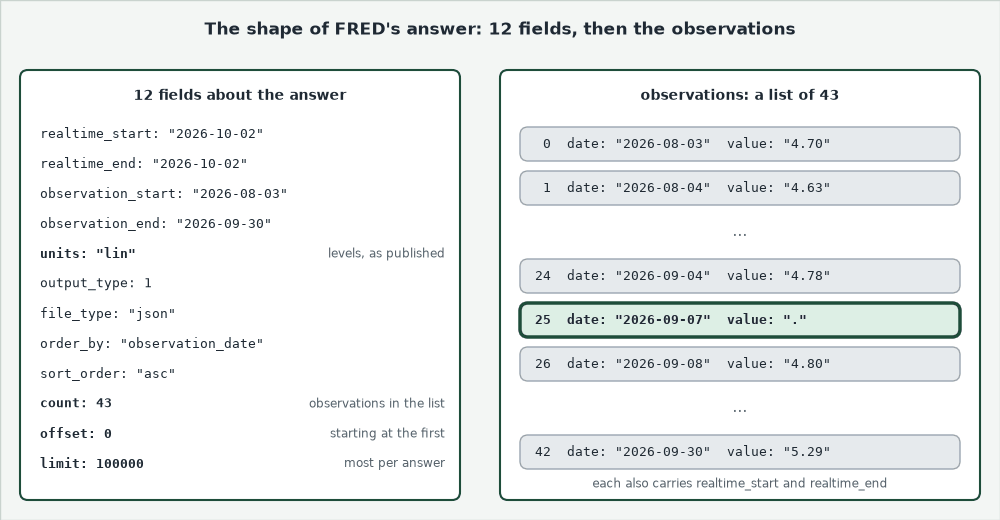

Twelve fields describe the answer; the 43 observations sit in a list of dicts.
`count`, `offset` and `limit`: 43 observations, starting at the first, at most 100,000 to an answer.

### The Observations as a Table

In [8]:
# a list of dicts becomes a table, one row per observation
obs = pd.DataFrame(payload['observations'])
print(obs.dtypes)
print(len(obs), 'rows; count says', payload['count'])

realtime_start    str
realtime_end      str
date              str
value             str
dtype: object
43 rows; count says 43


Every column is text, `value` included.

### The Days Around Labor Day

In [9]:
# rows 23 to 27: a label slice keeps its end
obs.loc[23:27, ['date', 'value']]

,date,value
23,2026-09-03,4.77
24,2026-09-04,4.78
25,2026-09-07,.
26,2026-09-08,4.80
27,2026-09-09,4.83


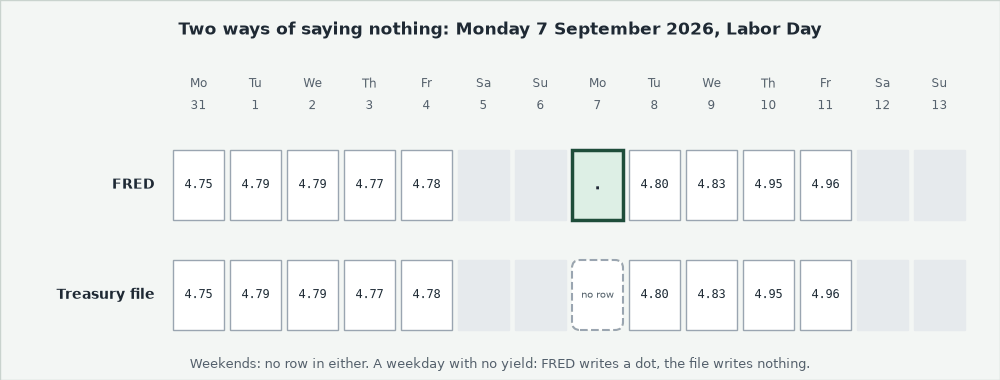

Monday 7 September 2026 was Labor Day: no Treasury yield.
FRED writes a row whose value is a dot; the Treasury file writes no row.

**Excel side by side.** Power Query reads the file (Data, Get Data, From Other Sources, Blank Query, Advanced Editor), every value as text.
For the counts, B2:B44 of a sheet hold the 43 values: 42 numbers and the text `.`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Read the answer</td><td align="left"><code>pd.DataFrame(payload['observations'])</code></td><td align="left"><code>Json.Document(File.Contents(...))</code>, then <code>Table.FromRecords(Source[observations])</code></td><td align="left">43 rows, <code>value</code> as text, <code>.</code> on 2026-09-07</td></tr>
<tr><td align="left">Count the rows</td><td align="left"><code>len(obs)</code></td><td align="left"><code>=COUNTA(B2:B44)</code></td><td align="left">43</td></tr>
<tr><td align="left">Count the numbers</td><td align="left"><code>len(obs) - (obs['value'] == '.').sum()</code></td><td align="left"><code>=COUNT(B2:B44)</code></td><td align="left">42</td></tr>
<tr><td align="left">Count the dots</td><td align="left"><code>(obs['value'] == '.').sum()</code></td><td align="left"><code>=COUNTIF(B2:B44,".")</code></td><td align="left">1</td></tr>
</table>
<br clear="left">

**FRED writes a row with a dot on a weekday with no yield, where the Treasury file writes no row at all: count rows and you count the dot.**

## 2.3 The Dot Is a Missing Day

Can Python read the dot as a number?

### Read the Dot as a Number

In [10]:
# float() reads text as a number
float('.')

ValueError: could not convert string to float: '.'

`pd.to_numeric` on the column stops at the same dot.

### Mark It Missing

In [11]:
# errors='coerce' turns text that is not a number into NaN, as in Course 1's EDA notebook
kept = pd.to_numeric(obs['value'], errors='coerce')
# the dates as dates, as the row labels
kept.index = pd.to_datetime(obs['date'])
print(kept.dtype, '|', kept.isna().sum(), 'NaN, on', kept.index[kept.isna()][0].date())

float64 | 1 NaN, on 2026-09-07


### Drop It, Then Tie It to the Treasury File

In [12]:
# dropna, a step you can see; then the Treasury file, read as in notebook 01
sample_10y = kept.dropna()
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
gap = (sample_10y - treasury.loc[sample_10y.index, '10 Yr']).abs().max()
print(len(kept), 'rows,', len(sample_10y), 'after dropna; largest gap', gap, 'percent')
print('2026-09-07 in the Treasury file:', pd.Timestamp('2026-09-07') in treasury.index)

43 rows, 42 after dropna; largest gap 0.0 percent
2026-09-07 in the Treasury file: False


### The Sample on the Snapshot

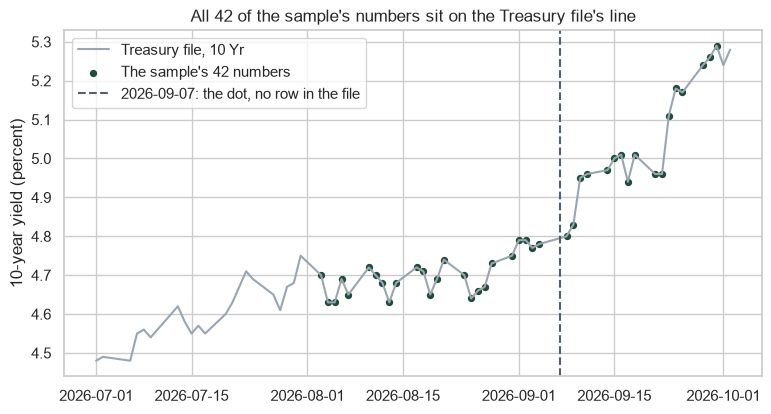

In [13]:
# the file's 10-year from July in grey, the sample's 42 numbers on top
window = treasury.loc['2026-07-01':, '10 Yr']
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(window.index, window, color='#9AA5B1', label='Treasury file, 10 Yr')
ax.scatter(sample_10y.index, sample_10y, s=18, color='#1E4D3A', label="The sample's 42 numbers")
ax.axvline(pd.Timestamp('2026-09-07'), color='#52606D', linestyle='--',
           label='2026-09-07: the dot, no row in the file')
ax.set_title("All 42 of the sample's numbers sit on the Treasury file's line")
ax.set_ylabel('10-year yield (percent)')
ax.legend(loc='upper left')
plt.show()

**Excel side by side.** B2 holds the text `.`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Read the dot as a number</td><td align="left"><code>float('.')</code></td><td align="left"><code>=VALUE(".")</code></td><td align="left"><code>#VALUE!</code></td></tr>
<tr><td align="left">Mark it missing</td><td align="left"><code>pd.to_numeric(..., errors='coerce')</code></td><td align="left"><code>=IFERROR(VALUE(B2),NA())</code></td><td align="left"><code>#N/A</code></td></tr>
<tr><td align="left">Drop it</td><td align="left"><code>kept.dropna()</code></td><td align="left">Power Query <code>Table.SelectRows(Rows, each [value] &lt;&gt; ".")</code>, before typing the column</td><td align="left">42 rows, every value a number</td></tr>
</table>
<br clear="left">

**42 numbers equal to the Treasury file, and the 43rd row is a day the market had no yield: the dot is a missing day, nothing else.**

## 2.4 What a Zero Would Do

The easy fix is a 0: the column stays numeric and nothing stops.

**Predict 2**

Q. Read the dot as 0. Friday 4 September is 4.78 and Tuesday 8 September 4.80. What change does Tuesday show, in bp? Write down a number.

### The Dot as 0, Against the Dot Dropped

In [14]:
# fillna(0.0) puts 0 where the NaN is; .diff() is each row less the row before
as_zero = kept.fillna(0.0)
changes = pd.DataFrame({'dot as 0': as_zero.diff() * 100, 'dot dropped': sample_10y.diff() * 100})
changes.loc['2026-09-03':'2026-09-08'].round(2)

,dot as 0,dot dropped
date,,
2026-09-03,-2.0,-2.0
2026-09-04,1.0,1.0
2026-09-07,-478.0,NaN
2026-09-08,480.0,2.0


480 bp on a Tuesday when the yield rose 2 bp: Monday falls 478 to zero and Tuesday climbs back.
Dropped, the dot leaves no Monday row (the table writes `NaN` there), and Tuesday's change is from Friday.

### Draw Both

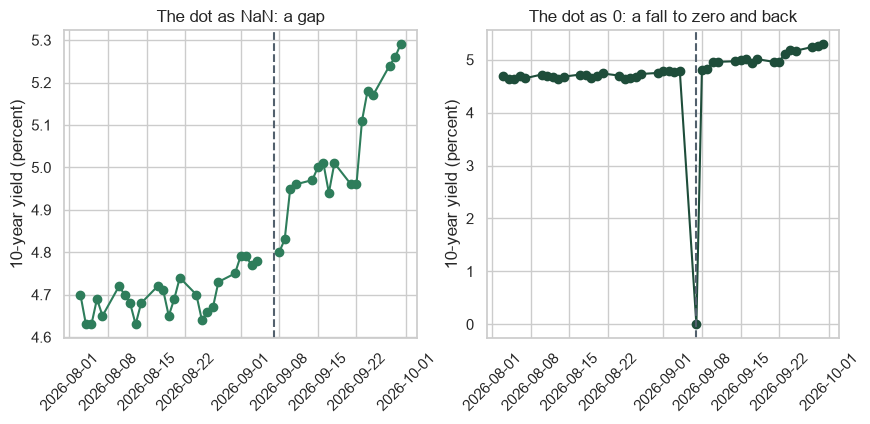

In [15]:
# two panels side by side; sharex=True gives them one date axis
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
axes[0].plot(kept.index, kept, marker='o')
axes[0].set_title('The dot as NaN: a gap')
axes[1].plot(as_zero.index, as_zero, marker='o', color='#1E4D3A')
axes[1].set_title('The dot as 0: a fall to zero and back')
for ax in axes:
    ax.axvline(pd.Timestamp('2026-09-07'), color='#52606D', linestyle='--')
    ax.set_ylabel('10-year yield (percent)')
    ax.tick_params(axis='x', rotation=45)
plt.show()

**Predict 3**

Q. Keep the `NaN` and call `.diff()` straight away. Tuesday shows:

A) 2 bp: pandas looks back to Friday
B) `NaN`
C) 480 bp: `NaN` counts as 0

### The Change With the NaN Still In

In [16]:
# the daily changes in bp, straight from the column with its NaN
(kept.diff() * 100).loc['2026-09-04':'2026-09-08'].round(2)

date
2026-09-04    1.0
2026-09-07    NaN
2026-09-08    NaN
Name: value, dtype: float64

B: a change needs two numbers and Monday has none, so Tuesday's change is missing too.
Drop first, then take changes, as `marketdata.py`'s docstring has said since notebook 01.

### And the Average

In [17]:
# the average yield both ways, in percent, and the gap in bp
print(f'Dot dropped: {sample_10y.mean():.4f} percent')
print(f'Dot as 0:    {as_zero.mean():.4f} percent')
print(f'Gap: {(sample_10y.mean() - as_zero.mean()) * 100:.1f} bp')

Dot dropped: 4.8367 percent
Dot as 0:    4.7242 percent
Gap: 11.2 bp


**Excel side by side.** Power Query loads the answer with its column typed; D is `value`, so D26 is Friday, D27 Monday, D28 Tuesday.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Type the column</td><td align="left"><code>pd.to_numeric(..., errors='coerce')</code></td><td align="left"><code>Table.TransformColumnTypes(Rows, {{"date", type date}, {"value", type number}}, "en-US")</code></td><td align="left">43 rows; the dot loads as an empty cell</td></tr>
<tr><td align="left">Tuesday's change</td><td align="left"><code>as_zero.diff() * 100</code></td><td align="left"><code>=(D28-D27)*100</code></td><td align="left">480: the empty cell read as 0</td></tr>
<tr><td align="left">From Friday</td><td align="left"><code>sample_10y.diff() * 100</code></td><td align="left"><code>=(D28-D26)*100</code></td><td align="left">1.9999999999999574</td></tr>
<tr><td align="left">A line chart</td><td align="left">the two panels</td><td align="left">a line chart of the values</td><td align="left">the text <code>.</code> plotted at 0; an empty cell left as a gap, by default</td></tr>
<tr><td align="left">The average</td><td align="left"><code>sample_10y.mean()</code></td><td align="left"><code>=AVERAGE(B2:B44)</code></td><td align="left">4.836666666666667: the text skipped</td></tr>
<tr><td align="left">The average, dot as 0</td><td align="left"><code>as_zero.mean()</code></td><td align="left"><code>=SUM(B2:B44)/ROWS(B2:B44)</code></td><td align="left">4.724186046511628</td></tr>
</table>
<br clear="left">

**A zero invents a 480 bp move and drags the average 11 bp: a dot becomes `NaN`, and `NaN` rows are dropped before any change or window.**

## 2.5 `fred_params` and `parse_fred_observations`

Now into the module, tested without the network.

![Five steps in a row: fred_params builds a dict and sends nothing; requests.get, lit, the only network step; status 200, anything else a RuntimeError; parse_fred_observations reads the answer, the dot becomes NaN; any rows, none a RuntimeError. Below, in the tests, monkeypatch swaps requests.get for a stand-in, so no test reaches FRED](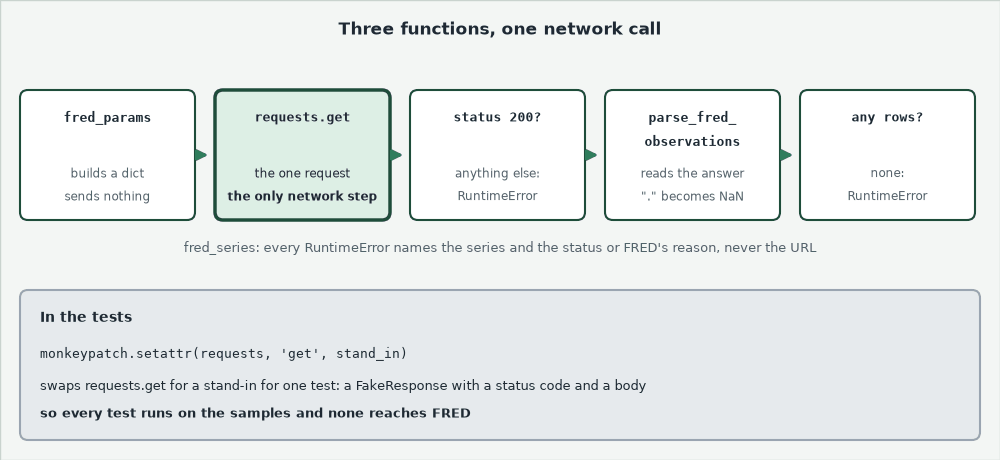)

`fred_params` builds the request and `parse_fred_observations` reads the answer; neither touches the network.
`fred_series`, in 2.6, joins them around the one request.

### Append `fred_params`

Read the docstring first.
`str | None` marks an argument that may be `None`, and `= None` makes it optional.
The imports sit with the day's code; in your own file you may move them to the top.

In [18]:
%%writefile -a marketdata.py


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params

Appending to marketdata.py


### The Sample's Parameters

In [19]:
# read the file again, so md holds fred_params
importlib.reload(md)
params = md.fred_params('DGS10', FAKE_KEY, start='2026-08-03', end='2026-09-30')
print(list(params))
# compare, never print: the dict holds the key
print('The key is the fake key:', params['api_key'] == FAKE_KEY)

['series_id', 'api_key', 'file_type', 'observation_start', 'observation_end']
The key is the fake key: True


`requests` joins these pairs after the `?`, as notebook 01's first picture drew.

### Append `parse_fred_observations`

`pd.to_datetime(format=)` reads every date in one pattern.
`float("nan")` makes a `NaN`; `pd.Series(values, index=, name=, dtype=)` names the series and fixes its type; `.index.name = "date"` names the index.

In [20]:
%%writefile -a marketdata.py


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series

Appending to marketdata.py


### Parse the Sample

In [21]:
# reload, then read the sample with the module's parser
importlib.reload(md)
dgs10 = md.parse_fred_observations(payload, 'DGS10')
print(len(dgs10), 'rows,', dgs10.isna().sum(), 'NaN,', dgs10.dtype, '| index:', dgs10.index.name)
print('Same numbers as 2.3 by hand:', (dgs10.dropna() == sample_10y).all())

43 rows, 1 NaN, float64 | index: date
Same numbers as 2.3 by hand: True


### Three Tests

`read_sample` reads a sample from the test file's own folder, `HERE`, as in Course 2.
`FakeResponse` is a class, as in Course 1's Classes notebook: a stand-in for FRED's answer, with a status code, a `.json()` method, and a URL holding the fake key.
`math.isnan` asks whether a number is `NaN`, which never equals itself, so `==` cannot.

In [22]:
%%writefile -a test_marketdata.py


import json  # the FRED-format samples, from day 2
import math  # NaN checks, from day 2
import traceback  # what a printed error would show, from day 2
from pathlib import Path  # this folder, from day 2

import pandas as pd  # dated series, from day 2
import requests  # its exception classes, from day 2

# the data files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_sample(series_id: str) -> dict:
    """A FRED-format sample from this folder: Treasury values in FRED's JSON layout, no network."""
    return json.loads((HERE / f"course3_fred_format_{series_id.lower()}.json").read_text(encoding="utf-8"))


class FakeResponse:
    """A stand-in for requests.Response: a status code, a JSON body, and a URL holding the key, no network."""

    def __init__(self, status_code: int, payload: dict):
        self.status_code = status_code
        self.payload = payload
        # a real response's URL holds the key; if fred_series ever printed it, the tests below would catch it
        self.url = f"{md.FRED_URL}?series_id=DGS10&api_key={FAKE_KEY}&file_type=json"

    def json(self) -> dict:
        return self.payload


def test_params_hold_series_and_json():
    params = md.fred_params("DGS10", FAKE_KEY, start="2015-01-01")
    assert params == {"series_id": "DGS10", "api_key": FAKE_KEY, "file_type": "json",
                      "observation_start": "2015-01-01"}
    # no end date asked for, so none is sent
    assert "observation_end" not in params


def test_parse_sample_counts_and_nan():
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    # 43 weekdays from 2026-08-03 to 2026-09-30, one of them FRED's "." on Labor Day
    assert len(series) == 43
    assert series.isna().sum() == 1
    assert math.isnan(series.loc["2026-09-07"])
    assert series.loc["2026-09-30"] == 5.29
    assert series.dtype == "float64"
    assert series.index.name == "date" and series.name == "DGS10"


def test_parse_raises_without_observations():
    with pytest.raises(ValueError):
        md.parse_fred_observations({"error_code": 400, "error_message": "Bad Request."}, "DGS10")

Appending to test_marketdata.py


### Run pytest

In [23]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......                                                                  [100%]
7 passed in 0.50s



**Two functions, neither touching the network: one builds the request, one reads the answer with the dot kept as `NaN`, and `7 passed` proves both.**

## 2.6 `fred_series`: Errors That Hide the Key

`fred_series` sends one request and hands the answer to the parser.
FRED answers 200 with the observations, 400 with its reason for a bad request, 429 over its limit (notebook 01's table).
Many tutorials and AI answers call `response.raise_for_status()`, which raises for any status from 400 to 599: its message holds the whole URL.

![One 400 refusal, two messages. Left, raise_for_status: 400 Client Error, Bad Request for url, then the whole URL with api_key equal to the fake key, lit. Right, fred_series: RuntimeError, FRED returned HTTP 400 for DGS10, then FRED's reason that the api_key is not registered; no URL, no key](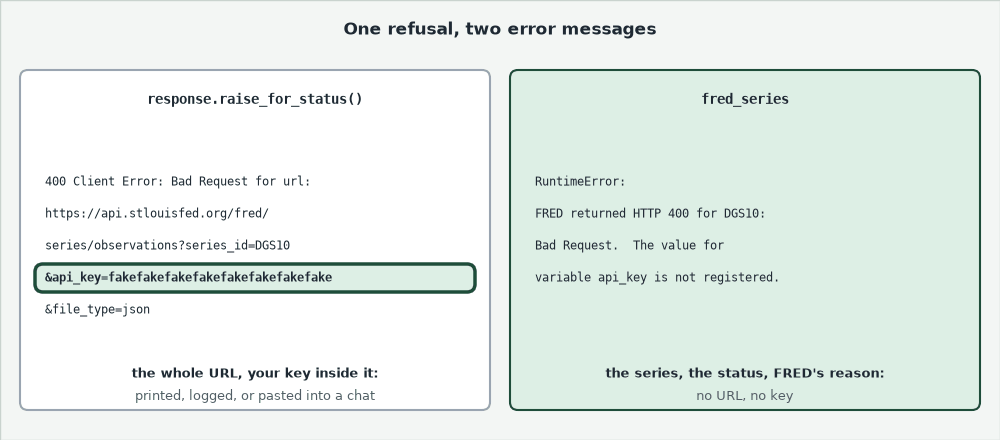)

Printed, logged, or pasted into a chat, the left one gives your key away.

### Append `fred_series`

Read the docstring first: its last lines are the promises.
`except requests.RequestException` and `raise ... from None` work as in notebook 01's live cell: the original error, URL and all, is never printed.

In [24]:
%%writefile -a marketdata.py


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series

Appending to marketdata.py


### Two Tests That Never Reach FRED

`monkeypatch.setattr(requests, "get", stand_in)` swaps `requests.get` for a stand-in for one test.
`traceback.format_exception` gives the text Python would print for an error.
After `from None`, `__cause__` is `None` and `__suppress_context__` is `True`: Python keeps the original error but never prints it.
`a | b` merges two dicts, the right one winning; `pd.testing.assert_series_equal` fails unless two series match in values, dates, dtype and name.

In [25]:
%%writefile -a test_marketdata.py


def test_fred_series_error_hides_key(monkeypatch):
    # an HTTP 400 answer with FRED's own message for a key that is not registered
    def fake_get_400(url, params, timeout):
        return FakeResponse(400, {"error_code": 400,
                                  "error_message": "Bad Request.  The value for variable api_key is not registered."})

    monkeypatch.setattr(requests, "get", fake_get_400)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert "HTTP 400" in str(caught.value) and "not registered" in str(caught.value)
    assert FAKE_KEY not in printed and "api_key=" not in printed

    # a connection error: requests puts the full URL, key included, in its message
    def fake_get_down(url, params, timeout):
        raise requests.ConnectionError(f"Max retries exceeded with url: /fred/series/observations?series_id=DGS10"
                                       f"&api_key={FAKE_KEY}&file_type=json")

    monkeypatch.setattr(requests, "get", fake_get_down)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert str(caught.value) == "Request for DGS10 failed: ConnectionError"
    # raised from None: no chained traceback carries the original message
    assert caught.value.__cause__ is None and caught.value.__suppress_context__
    assert FAKE_KEY not in printed and "api_key=" not in printed


def test_fred_series_empty_raises(monkeypatch):
    # FRED answers a range the series does not cover with HTTP 200 and no observations
    empty = read_sample("DGS10") | {"count": 0, "observations": []}
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, empty))
    with pytest.raises(RuntimeError):
        md.fred_series("DGS10", FAKE_KEY, start="2010-01-01", end="2010-12-31")
    # the same stand-in with the sample's observations parses as the sample does
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, read_sample("DGS10")))
    pd.testing.assert_series_equal(md.fred_series("DGS10", FAKE_KEY),
                                   md.parse_fred_observations(read_sample("DGS10"), "DGS10"))

Appending to test_marketdata.py


### Run pytest

In [26]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........                                                                [100%]
9 passed in 0.50s



In [27]:
# read the file again, so md holds the function
importlib.reload(md)
print('fred_series is in the module:', 'fred_series' in dir(md))

fred_series is in the module: True


**`fred_series` reports the status and FRED's own reason, never the URL, and a test that formats the whole error proves no key survives in it.**

## 2.7 Live: the 10-Year and the 2-Year From 2015

*This product uses the FRED&reg; API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

FRED's API terms ask every application that uses the API to show that notice (https://fred.stlouisfed.org/docs/api/terms_of_use.html, read 2026-11-08).
The key cell and live cells work as in notebook 01.

### The Key Cell

In [28]:
from pathlib import Path

# your .env file: in my_bondmath, outside every repository. The key cell looks here last.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"
# what every live cell prints when no key was found
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."

In [29]:
try:
    fred_key = md.get_secret("FRED_API_KEY", env_file=ENV_FILE)
    print("FRED key: found. It is held in memory and is never printed.")
except RuntimeError as error:
    fred_key = None
    print(f"FRED key: not found. Live cells will be skipped. {error}")

FRED key: not found. Live cells will be skipped. Secret FRED_API_KEY not found. Looked in: the environment variable FRED_API_KEY, Colab's Secrets panel, and the file .env given as env_file.


### FRED Refuses the Fake Key

In [30]:
# a live cell: it uses the network, and sends only the course's fake key
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    live_message = None
    try:
        md.fred_series('DGS10', FAKE_KEY, start='2026-09-01')
    except RuntimeError as live_error:
        live_message = str(live_error)
    # check before printing: a 400 from FRED, and no key and no URL in the message
    assert live_message is not None and 'HTTP 400' in live_message
    assert FAKE_KEY not in live_message and 'api_key=' not in live_message
    print(live_message)

Live cell skipped: no FRED key was found. Every other cell runs without one.


### Pull and Tie

In [31]:
# a live cell: two requests to FRED with your key
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    for live_id, live_column in [('DGS10', '10 Yr'), ('DGS2', '2 Yr')]:
        # one request per series; '.' rows come back as NaN
        live_series = md.fred_series(live_id, fred_key, start='2015-01-01')
        live_numbers = live_series.dropna()
        live_dots = live_series.index[live_series.isna()]
        # intersection: the dates in both; on each, FRED must equal the file
        live_common = live_numbers.index.intersection(treasury.index)
        live_gap = (live_numbers[live_common] - treasury.loc[live_common, live_column]).abs().max()
        assert len(live_common) > 0 and live_gap <= 1e-9, f'{live_id} and the file disagree'
        # and every dot falls on a date the file has no row for
        assert not live_dots.isin(treasury.index).any(), f'{live_id}: a dot on a file date'
        print(f'{live_id}: {len(live_series):,} rows, {len(live_dots)} dots,',
              f'last {live_series.index[-1].date()}; {len(live_common):,} dates in both,',
              f'largest gap {live_gap:.1e} percent')

Live cell skipped: no FRED key was found. Every other cell runs without one.


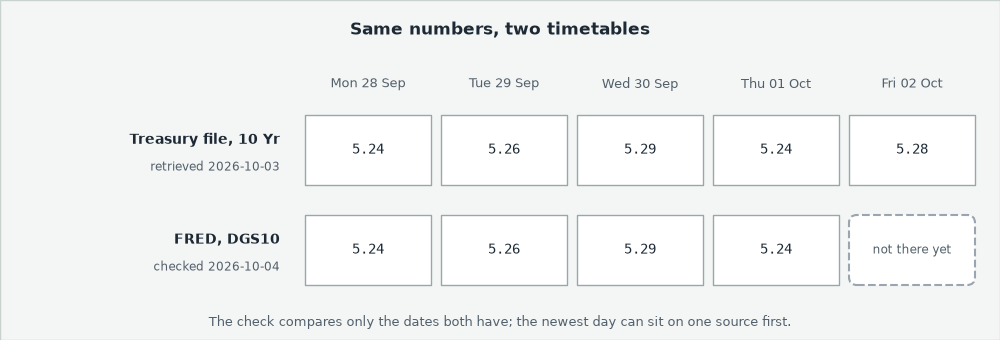

With your key, the first cell prints FRED's refusal, status and reason, and no key; the second prints one line per series: its rows since 2015, its dots, its last date, and the dates it shares with the file, at a largest gap of 0.
The two sources publish the same numbers on different schedules, so the newest day can sit on one a day before the other; the check compares only dates both have.

**With your key, both series pull through `fred_series` and equal the Treasury file on every date both have.**

## 2.8 120 Requests a Minute

FRED: "Up to 120 requests per minute are allowed before being served a 429 error code" (https://fred.stlouisfed.org/docs/api/fred/errors.html, read 2026-11-08).
Each call of `fred_series` is one request, so a loop that pulls all 11 Treasury tenors sends 11 a run.

**Predict 4**

Q. You run that loop again and again. On which run within one minute does FRED first answer 429? Write down a number.

### Count the Requests

In [32]:
# 12 runs of the loop, 11 requests each; runs past the limit in dark green
runs = list(range(1, 13))
requests_made = [11 * run for run in runs]
colours = ['#1E4D3A' if made > 120 else '#9AA5B1' for made in requests_made]

### Draw Them

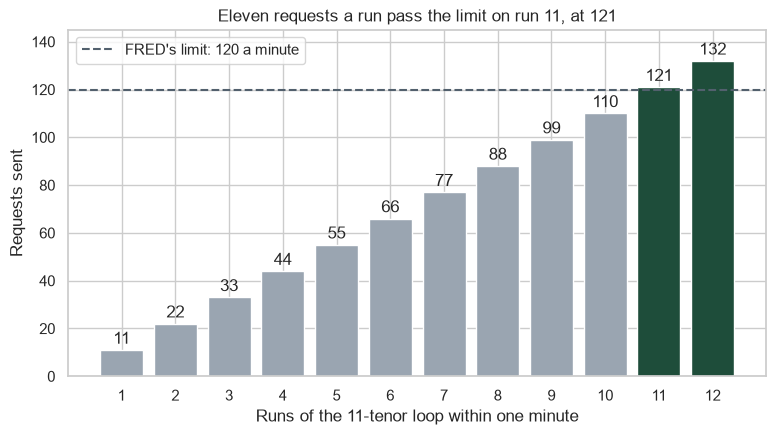

In [33]:
# the bars with their counts on top, and the limit as a dashed line
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(runs, requests_made, color=colours, tick_label=runs)
ax.bar_label(bars, padding=2)
ax.axhline(120, color='#52606D', linestyle='--', label="FRED's limit: 120 a minute")
ax.set_ylim(0, 145)
ax.set_title('Eleven requests a run pass the limit on run 11, at 121')
ax.set_xlabel('Runs of the 11-tenor loop within one minute')
ax.set_ylabel('Requests sent')
ax.legend(loc='upper left')
plt.show()

**Excel side by side.** `=INT(120/11)+1` returns 11: the whole runs inside the limit, plus one.

**Eleven requests a run are safe once and over the limit on the eleventh run in a minute: pull once and keep what you pulled (notebook 05 caches it).**

## 2.9 Read the Staged Change, Then Scan for Keys

The note's last ask.
Every `!` line names the work folder with `-C "{work}"`, as in notebook 01.

### What Changed, Then Stage It

The tests read the sample, which `start_day` copies every day: it stays out of the record.

In [34]:
!git -C "{work}" status --short
!git -C "{work}" add marketdata.py test_marketdata.py

 M marketdata.py
 M test_marketdata.py


**Predict 5**

Q. The two files are staged. What does plain `git diff --stat` print now?

A) the same two files
B) nothing
C) an error: there is no change

### Ask `git diff`

In [35]:
!git -C "{work}" diff --stat

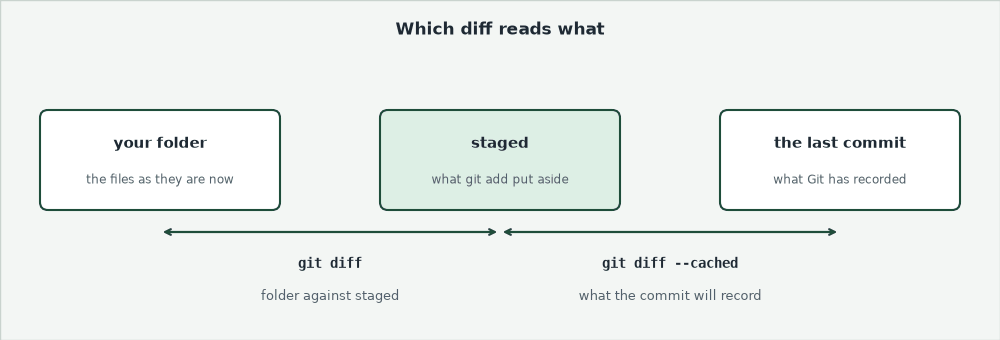

B: plain `git diff` compares your folder with the staging area, and since `add` they match.
`git diff --cached` compares the staging area with the last commit: what the commit will record.

### What the Commit Will Record, Line by Line

In [36]:
!git -C "{work}" diff --cached --stat
!git -C "{work}" diff --cached marketdata.py

 marketdata.py      | 84 ++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 94 ++++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 178 insertions(+)
diff --git a/marketdata.py b/marketdata.py
index 9a24a8c..f15a4f2 100644
--- a/marketdata.py
+++ b/marketdata.py
@@ -56,3 +56,87 @@ def get_secret(name: str, env_file: str | Path) -> str:
         f"Secret {name} not found. Looked in: the environment variable {name}, "
         f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
     )
+
+
+import pandas as pd  # dated series, from day 2
+import requests  # HTTP, from day 2
+
+# FRED's endpoint for the observations of one series
+FRED_URL = "https://api.stlouisfed.org/fred/series/observations"
+
+
+def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
+    """The query parameters for one request to FRED's series/observations endpoint.
+
+    Units: start and end are dates as te

After three lines of context, every line starts with `+`: today added code and changed none.

### Scan for a Key

`git grep` searches the files Git tracks; `--cached`, as in `diff`, reads the staged copies, exactly what the commit will hold.
`-n` adds line numbers, and `-E` reads the pattern as in Course 1's Analyzing Text: `[a-z0-9]` one lowercase letter or digit, `{32}` thirty-two in a row, a key's shape.

In [37]:
# IPython reads { } in a ! line as Python, so the braces are doubled
!git -C "{work}" grep --cached -n -E "[a-z0-9]{{32}}"

test_marketdata.py:12:FAKE_KEY = "fakefakefakefakefakefakefakefake"


One hit, the course's fake key, where the tests keep it: expected.
A real key found only staged: take it out of the file and stage again, or unstage with Course 2's `git restore --staged`.
A real key already in a commit: rotate it first, as notebook 01's drill showed.

### Commit

In [38]:
# the day's subject, then one line of body
subject = 'Notebook 02: fred_params, parse_fred_observations, and fred_series'
body = 'Pure functions build the request and read the answer; fred_series never shows the key.'
!git -C "{work}" commit -q -m "{subject}" -m "{body}"
!git -C "{work}" log --oneline

f3002d2 Notebook 02: fred_params, parse_fred_observations, and fred_series
a28686d Notebook 01: get_secret, a .gitignore, and .env.example


**The commit holds two files, read line by line and scanned: one 32-character run, the course's fake key, where the tests keep it.**

## Bring It Home

Copy the work folder's two files into `my_bondmath`, with the two samples the tests read, test them, scan, and commit.
The copy replaces your two files, so anything of your own must be in the work folder first.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_02_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py" .
# the samples: read by the tests, never committed
Copy-Item "$work\course3_fred_format_dgs10.json", "$work\course3_fred_format_dgs2.json" .
python -m pytest -q test_marketdata.py
git add marketdata.py test_marketdata.py
git diff --cached --stat
git grep --cached -n -E "[a-z0-9]{32}"
git commit -m "Notebook 02: fred_params, parse_fred_observations, and fred_series"
```

pytest shows `9 passed`; in PowerShell the braces are single, and `git grep` never reads your ignored `.env`.
Restart this notebook and run all cells: with your key, the live cells pull FRED.
In Colab, download the two files from the work folder under `/tmp`.

## You Can Now

By the end of this notebook, you can:

* Read JSON with `json.loads`, and say what each piece becomes in Python.
* Find FRED's missing marker, the dot, and say why the Treasury file has no row there.
* Keep a missing day as `NaN`, drop it in a step you can see, and show what a 0 would do.
* Build a request with `fred_params` and read an answer with `parse_fred_observations`, tested without the network.
* Download a series with `fred_series`, whose errors never show the key, proved with `monkeypatch`.
* Tie a live pull to the Treasury file, and stay inside FRED's 120 requests a minute.
* Read a staged change with `git diff --cached`, and scan it for a key with `git grep`.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and the two samples.

In [39]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [40]:
# the two samples as dicts: the 10-year and the 2-year
sample10 = json.loads(Path('course3_fred_format_dgs10.json').read_text(encoding='utf-8'))
sample2 = json.loads(Path('course3_fred_format_dgs2.json').read_text(encoding='utf-8'))
print(sample10['count'], 'and', sample2['count'], 'observations')

43 and 43 observations


### Exercise 1

Q. Parse `sample2` with `md.parse_fred_observations`, named `'DGS2'`. Store its value on 2026-09-30 in **ex1_value**.

In [41]:
ex1_value = ...

In [42]:
check('Exercise 1 the 2-year on 2026-09-30', ex1_value, 4.88)

Exercise 1 the 2-year on 2026-09-30: not attempted yet


### Exercise 2

Q. Straight from `sample10`, with no pandas, list the dates whose value is `'.'` with a comprehension that filters. Store how many there are in **ex2_dots** and the first date in **ex2_date**.

In [43]:
ex2_dots = ...
ex2_date = ...

In [44]:
check('Exercise 2 the number of dots', ex2_dots, 1)
check('Exercise 2 the date of the dot', ex2_date, '2026-09-07')

Exercise 2 the number of dots: not attempted yet
Exercise 2 the date of the dot: not attempted yet


### Exercise 3

Q. Add `observation_count(payload)`, docstring first: a dict of `'total'`, `'numeric'` and `'missing'` observations, and `ValueError` when the answer has no `observations` or its `count` disagrees with the list. Add `test_observation_count_sample`, on `read_sample('DGS2')` and on a copy made with `| {'count': 99}`. Run pytest, reload, and store `md.observation_count(sample2)` in **ex3_counts**.

In [45]:
%%writefile -a marketdata.py


# Exercise 3: write observation_count(payload) below this line

Appending to marketdata.py


In [46]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_observation_count_sample() below this line

Appending to test_marketdata.py


In [47]:
# run pytest as in the lesson, reload the module, then call your function
ex3_counts = ...

In [48]:
check('Exercise 3 the counts', ex3_counts, {'total': 43, 'numeric': 42, 'missing': 1})

Exercise 3 the counts: not attempted yet


### Exercise 4: AI check

You gave an assistant the docstring below as the prompt; the function came back, written for this course in the style of an assistant's answer, and holds one bug.

In [49]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def parse_yields(payload, name):
    """Turn a FRED series/observations answer into a float series indexed by date.

    Units: percent, as FRED publishes. Convention: FRED's missing marker "." becomes NaN and is
    kept, so a day with no yield never looks like a yield of 0.
    """
    dates = pd.to_datetime([obs['date'] for obs in payload['observations']])
    # "." becomes 0.0, so the column stays numeric
    values = [0.0 if obs['value'] == '.' else float(obs['value'])
              for obs in payload['observations']]
    return pd.Series(values, index=dates, name=name)

Q. What does it give for 2026-09-07? Run the test under it.

In [50]:
# the test, written from the docstring before the code is trusted
result = parse_yields(sample10, 'DGS10')
assert (result == 0).sum() == 0, 'a yield of 0 percent'
assert result.isna().sum() == 1, 'the dot did not become NaN'
print('No yield is 0, and the dot is NaN')

AssertionError: a yield of 0 percent

Q. Fix the function, then run it and the test again until the test passes. Store whether `parse_yields(sample10, 'DGS10')` is `NaN` on 2026-09-07 in **ex4_holiday_is_nan**, and how many of its values are 0 in **ex4_zero_count**.

In [51]:
ex4_holiday_is_nan = ...
ex4_zero_count = ...

In [52]:
check('Exercise 4 Labor Day is NaN', ex4_holiday_is_nan, True)
check('Exercise 4 no yield is 0', ex4_zero_count, 0)

Exercise 4 Labor Day is NaN: not attempted yet
Exercise 4 no yield is 0: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">What is in the answer</td><td align="left">12 fields and 43 observations, every value text</td></tr>
<tr><td align="left">A weekday with no yield</td><td align="left">A dot, on 2026-09-07, a day the Treasury file has no row for</td></tr>
<tr><td align="left">What a zero would do</td><td align="left">A 480 bp move that never happened, the average 11.2 bp low</td></tr>
<tr><td align="left">Three functions, tested</td><td align="left"><code>fred_params</code>, <code>parse_fred_observations</code>, <code>fred_series</code>, 9 passed</td></tr>
<tr><td align="left">Errors without a key</td><td align="left">The status and FRED's reason, raised <code>from None</code></td></tr>
<tr><td align="left">The 10-year and 2-year live</td><td align="left">Tied to the file on every common date</td></tr>
<tr><td align="left">FRED's limit</td><td align="left">120 a minute, passed on the eleventh 11-tenor run</td></tr>
<tr><td align="left">Read and scanned</td><td align="left"><code>git diff --cached</code>, one expected hit</td></tr>
</table>
<br clear="left">

Be proud: every FRED number in this course now comes through functions you wrote and tested.

Next: Market Calendars and Cleaning (notebook 03) asks which days the market really had.